# Qwen3.6-27B Zero-Shot Evaluation

## 1. Model & Experiment Overview

Qwen3.6-27B is a 27-billion-parameter generative model from the Qwen family. In this experiment, it received a single instruction and a math word problem and generated an `ANSWERABLE` or `UNANSWERABLE` label based on the information in the question. The task was zero-shot, with no demonstrations or task-specific fine-tuning. This notebook analyzes saved results.

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'notebooks').is_dir() and (path / 'data/processed').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start from the CDS1092 project root or notebooks directory.')

RESULTS_DIR = PROJECT_ROOT / 'results/llm/qwen3.6-27b'
RUN_ID = 'run_01'
LABELS = ['ANSWERABLE', 'UNANSWERABLE']
PREDICTED_LABELS = [*LABELS, 'INVALID']
METRICS = {
    'Accuracy': 'accuracy',
    'Precision (UNANSWERABLE)': 'precision_unanswerable',
    'Recall (UNANSWERABLE)': 'recall_unanswerable',
    'F1 (UNANSWERABLE)': 'f1_unanswerable',
}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def load_evaluation(dataset, expected_examples):
    directory = RESULTS_DIR / dataset / RUN_ID
    metrics = json.loads((directory / 'metrics.json').read_text(encoding='utf-8'))
    matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col='true_label')
    run = metrics['run']

    if (run['dataset'], run['run_id'], metrics['positive_class']) != (dataset, RUN_ID, LABELS[1]):
        raise ValueError(f'{directory}: unexpected run identity or positive class')
    if (list(matrix.index) != LABELS or list(matrix.columns) != PREDICTED_LABELS
            or metrics['confusion_matrix_rows'] != LABELS
            or metrics['confusion_matrix_columns'] != PREDICTED_LABELS):
        raise ValueError(f'{directory}: unexpected matrix labels or order')
    if (not all(pd.api.types.is_integer_dtype(dtype) for dtype in matrix.dtypes)
            or (matrix < 0).any().any() or matrix.values.tolist() != metrics['confusion_matrix']):
        raise ValueError(f'{directory}: CSV and JSON confusion counts disagree or are invalid')
    if not (matrix.values.sum() == metrics['num_examples'] == run['row_count'] == expected_examples):
        raise ValueError(f'{directory}: unexpected number of examples')

    tn, fp, invalid_negative = matrix.loc[LABELS[0]]
    fn, tp, invalid_positive = matrix.loc[LABELS[1]]
    missed = fn + invalid_positive

    def ratio(numerator, denominator):
        return numerator / denominator if denominator else 0.0

    expected = {
        'accuracy': (tn + tp) / expected_examples,
        'precision_unanswerable': ratio(tp, tp + fp),
        'recall_unanswerable': ratio(tp, tp + missed),
        'f1_unanswerable': ratio(2 * tp, 2 * tp + fp + missed),
        'num_invalid': invalid_negative + invalid_positive,
        'invalid_rate': (invalid_negative + invalid_positive) / expected_examples,
    }
    for key, value in expected.items():
        if not math.isclose(metrics[key], value, rel_tol=0, abs_tol=1e-12):
            raise ValueError(f'{directory}: {key} disagrees with the saved confusion counts')
    return metrics, matrix


sum_metrics, sum_matrix = load_evaluation('sum', 10944)
umwp_metrics, umwp_matrix = load_evaluation('umwp', 5200)

In [2]:
settings = {
    'Model': 'model_id',
    'Weights path': 'model_path',
    'Chat template': 'chat_template',
    'Precision': 'dtype',
    'Quantization': 'quantization',
    'GPU': 'gpu',
    'Requested temperature': 'requested_temperature',
    'Sampling enabled': 'do_sample',
    'Number of beams': 'num_beams',
    'Maximum new tokens': 'max_new_tokens',
    'PyTorch': 'torch_version',
    'Transformers': 'transformers_version',
    'CUDA': 'cuda_version',
}
run = sum_metrics['run']
for key in (*settings.values(), 'prompt', 'model_sha256', 'invalid_output_policy'):
    if run[key] != umwp_metrics['run'][key]:
        raise ValueError(f'Saved runs disagree on {key}')

configuration = {
    label: 'None' if run[key] is None else str(run[key])
    for label, key in settings.items()
}
configuration['Decoding'] = 'Greedy' if not run['do_sample'] and run['num_beams'] == 1 else 'See settings'
display(pd.Series(configuration, name='Recorded setting').rename_axis('Setting').to_frame())
display(Markdown('**Exact prompt**\n\n```text\n' + run['prompt'] + '\n```'))

,Recorded setting
Setting,
Model,Qwen/Qwen3.6-27B
Weights path,models/Qwen3.6-27B
Chat template,"model default, user message only, enable_think..."
Precision,bfloat16
Quantization,None
GPU,NVIDIA A100 80GB PCIe
Requested temperature,0
Sampling enabled,False
Number of beams,1


**Exact prompt**

```text
Determine whether the following math problem can be answered using the information provided.

Respond with exactly one label:
ANSWERABLE or UNANSWERABLE.

Do not solve the problem or provide an explanation.

Math problem:
{question}

Label:
```

## 2. Evaluation Metrics

**UNANSWERABLE is the positive class.**

- **Accuracy** is the fraction of all questions assigned the correct label.
- **Precision** is the fraction of predicted UNANSWERABLE questions that are truly unanswerable.
- **Recall** is the fraction of truly unanswerable questions detected by the model.
- **F1** is the harmonic mean of precision and recall for UNANSWERABLE.

Confusion matrices show actual labels in rows and predicted labels in columns. A false positive flags an answerable question as unanswerable. A false negative marks an unanswerable question as answerable, which can lead a downstream solver to attempt a question with insufficient information. The INVALID column tracks responses outside the two permitted labels. Each heatmap scales its colors to its own counts.

In [3]:
if sum_metrics['invalid_output_policy'] != umwp_metrics['invalid_output_policy']:
    raise ValueError('Saved runs disagree on the invalid-output policy')
display(Markdown('**Recorded scoring policy.** ' + sum_metrics['invalid_output_policy']))


def show_evaluation(name, metrics, matrix):
    summary = {
        'Examples': f"{metrics['num_examples']:,}",
        **{label: f'{metrics[key]:.6f}' for label, key in METRICS.items()},
        'Invalid outputs': f"{metrics['num_invalid']:,} ({metrics['invalid_rate']:.2%})",
    }
    display(pd.DataFrame([summary], index=pd.Index([name], name='Dataset')))

    fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
    values = matrix.to_numpy()
    limit = values.max()
    ax.imshow(values, cmap='Blues', vmin=0, vmax=limit, aspect='auto')
    for (row, column), value in matrix.stack().items():
        ax.text(matrix.columns.get_loc(column), matrix.index.get_loc(row), f'{value:,}',
                ha='center', va='center', color='white' if value > limit / 2 else 'black')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted label', ylabel='Actual label', title=f'{name} confusion matrix')
    plt.show()
    plt.close(fig)


def describe_errors(matrix):
    fp = matrix.loc['ANSWERABLE', 'UNANSWERABLE']
    fn = matrix.loc['UNANSWERABLE', 'ANSWERABLE']
    answerable = matrix.loc['ANSWERABLE'].sum()
    unanswerable = matrix.loc['UNANSWERABLE'].sum()
    return (
        f'The model flagged **{fp:,}** answerable problems as unanswerable '
        f'({fp / answerable:.2%} of answerable problems). It marked **{fn:,}** unanswerable '
        f'problems as answerable ({fn / unanswerable:.2%} of unanswerable problems).'
    )

**Recorded scoring policy.** After trimming surrounding whitespace, only exact uppercase labels are valid. INVALID is incorrect for accuracy and is a separate confusion-matrix column. INVALID on a true UNANSWERABLE row counts as a missed positive for recall and F1. Precision uses all predicted UNANSWERABLE rows. Zero denominators yield zero.

## 3. SUM Results & Analysis

SUM Test is the held-out split of the Synthetic Unanswerable Math benchmark. The analysis uses the complete saved test run.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
SUM Test,"10,944",0.881031,0.908663,0.847222,0.876868,0 (0.00%)


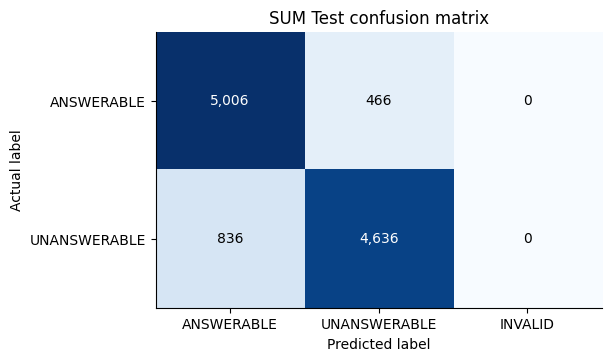

Accuracy on SUM Test was **88.10%**, with an UNANSWERABLE F1 of **87.69%**. The model flagged **466** answerable problems as unanswerable (8.52% of answerable problems). It marked **836** unanswerable problems as answerable (15.28% of unanswerable problems). UNANSWERABLE precision was 90.87%, while recall was 84.72%. The observed errors suggest that treating a problem as answerable is the more frequent misclassification on this split.

In [4]:
show_evaluation('SUM Test', sum_metrics, sum_matrix)
display(Markdown(
    f"Accuracy on SUM Test was **{sum_metrics['accuracy']:.2%}**, with an UNANSWERABLE "
    f"F1 of **{sum_metrics['f1_unanswerable']:.2%}**. {describe_errors(sum_matrix)} "
    f"UNANSWERABLE precision was {sum_metrics['precision_unanswerable']:.2%}, "
    f"while recall was {sum_metrics['recall_unanswerable']:.2%}. "
    'The observed errors suggest that treating a problem as answerable is the more '
    'frequent misclassification on this split.'
))

## 4. UMWP Results & Analysis

UMWP is an external mathematical word problem benchmark. The analysis uses the complete saved UMWP run.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
UMWP,"5,200",0.931923,0.941084,0.921538,0.931209,0 (0.00%)


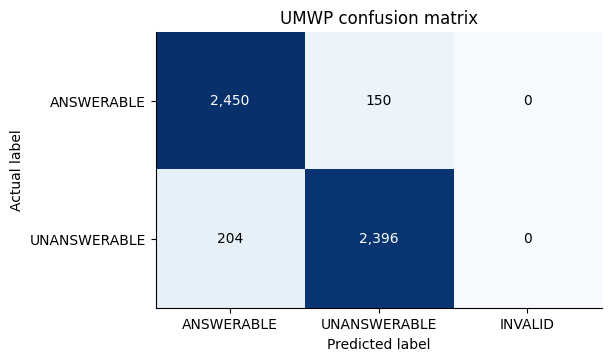

Accuracy on UMWP was **93.19%**, with an UNANSWERABLE F1 of **93.12%**. The model flagged **150** answerable problems as unanswerable (5.77% of answerable problems). It marked **204** unanswerable problems as answerable (7.85% of unanswerable problems). The model correctly flagged 92.15% of truly unanswerable questions. Of the questions it flagged, 94.11% were truly unanswerable. The missed detections quantify the risk of passing an unanswerable problem to a solver.

In [5]:
show_evaluation('UMWP', umwp_metrics, umwp_matrix)
display(Markdown(
    f"Accuracy on UMWP was **{umwp_metrics['accuracy']:.2%}**, with an UNANSWERABLE "
    f"F1 of **{umwp_metrics['f1_unanswerable']:.2%}**. {describe_errors(umwp_matrix)} "
    f"The model correctly flagged {umwp_metrics['recall_unanswerable']:.2%} of truly "
    f"unanswerable questions. Of the questions it flagged, "
    f"{umwp_metrics['precision_unanswerable']:.2%} were truly unanswerable. "
    'The missed detections quantify the risk of passing an unanswerable problem to a solver.'
))